# Notebook 06: The 2025 temporal test

**Study:** predicting recorded road casualty severity (KSI) in Great Britain. This notebook carries out section 3.7.4 and Table 3.3: the main evaluation on 2025, after the freeze.

**This notebook opens the sealed 2025 labels.** Nothing in the predictors, settings, thresholds or model choice may change after this point. Any change from here is a departure from the plan and has to be logged as one.

**What it does**
1. Checks the freeze record, the saved 2025 scores and the sealed labels are exactly the files that were frozen. Writes an unsealing log.
2. Joins the labels to the scores and checks the 2025 KSI total against Table 3.2.
3. Computes every Table 3.3 measure for the nine model and training combinations at the two frozen thresholds: KSI recall, precision, specificity, confusion matrix, macro-F1, balanced accuracy, average precision, ROC-AUC, Brier score, calibration intercept (slope fixed at one) and calibration slope.
4. Runs the paired collision bootstrap (2,000 replicates, 95% percentile intervals). Every model sees the same draws, so differences between models are paired.
5. Draws reliability plots (quantile bins, tied scores kept together) and compares 2025 with the development scores.

**To run it:** set `UNSEAL = True` in the setup cell. It is False by default so the labels cannot be opened by accident.

In [2]:
# 1. Setup and the unseal gate -------------------------------------------------------------
import os, sys, json, hashlib, subprocess, time, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
try:
    display
except NameError:
    display = print

UNSEAL = True         # set True only when you are ready to open the sealed 2025 labels
BOOT_REPS = 2000       # paired collision bootstrap replicates (Chapter 3, Table 3.3)

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/stats19_severity')
else:
    PROJECT = Path(os.environ.get('PROJECT_DIR', './stats19_severity'))
CODE = PROJECT / 'code'; MOD = PROJECT / 'outputs' / 'models'; FINAL = MOD / 'final'; SEARCH = MOD / 'search'
RES = PROJECT / 'outputs' / 'results'; ENV = PROJECT / 'environment'; SEALED = PROJECT / 'data' / 'sealed_2025_labels'
RES.mkdir(parents=True, exist_ok=True)
SEED = 20261107
BOOT_SEED = SEED + 2
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
(ENV / 'pip_freeze_notebook06.txt').write_text(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
print('scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)
if not UNSEAL:
    print('\nUNSEAL is False. Nothing has been opened. Set UNSEAL = True above and rerun when you are ready.')
    raise SystemExit

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
scikit-learn 1.6.1 | matplotlib 3.10.0


In [3]:
# 2. Evaluation helpers, saved to Drive ------------------------------------------------
MODULE = r'''"""Evaluation helpers for the STATS19 severity study (notebooks 06 onward).
Everything here is label-agnostic code: it only runs once the sealed 2025 labels are opened in notebook 06."""
import numpy as np
from scipy.special import expit, logit

CLIP = 1e-6                      # probabilities are clipped to [CLIP, 1 - CLIP] only for the logit calculation

def clip_logit(p):
    return logit(np.clip(p, CLIP, 1 - CLIP))

def irls_logistic(x, y, w=None, fit_slope=True, start=(0.0, 1.0), iters=60, tol=1e-9):
    """Weighted logistic regression of y on x. fit_slope=False fixes the slope at 1 (intercept only).
    Returns (intercept, slope)."""
    w = np.ones(len(y)) if w is None else w
    a, b = start if fit_slope else (start[0], 1.0)
    for _ in range(iters):
        mu = expit(a + b * x)
        s = w * mu * (1.0 - mu)
        r = w * (y - mu)
        if fit_slope:
            sx = (s * x).sum()
            H = np.array([[s.sum(), sx], [sx, (s * x * x).sum()]])
            step = np.linalg.solve(H, np.array([r.sum(), (r * x).sum()]))
            a += step[0]; b += step[1]
        else:
            step = np.array([r.sum() / s.sum()]); a += step[0]
        if np.max(np.abs(step)) < tol:
            break
    return float(a), float(b)

class RankPrep:
    """Pre-sorts scores once so weighted average precision and ROC-AUC are cheap inside a bootstrap loop.
    Tied scores form one threshold step, as in scikit-learn."""
    def __init__(self, p, y):
        order = np.argsort(-p, kind='mergesort')
        ps = p[order]
        new = np.r_[True, ps[1:] != ps[:-1]]
        self.gid = np.cumsum(new) - 1
        self.ng = int(self.gid[-1]) + 1
        self.order = order
        self.ys = y[order].astype(float)
    def ap_auc(self, w):
        ws = w[self.order]
        pos = np.bincount(self.gid, weights=ws * self.ys, minlength=self.ng)
        neg = np.bincount(self.gid, weights=ws * (1.0 - self.ys), minlength=self.ng)
        tp, fp = np.cumsum(pos), np.cumsum(neg)
        P, N = tp[-1], fp[-1]
        den = tp + fp
        prec = np.divide(tp, den, out=np.zeros_like(tp), where=den > 0)
        rec, fpr = tp / P, fp / N
        ap = float(np.sum(np.diff(np.r_[0.0, rec]) * prec))
        auc = float(np.sum(np.diff(np.r_[0.0, fpr]) * (np.r_[0.0, rec[:-1]] + rec) / 2.0))
        return ap, auc

def decision_rates(c):
    """c[..., 0:4] = tp, fp, fn, tn. Returns the Table 3.3 decision measures."""
    c = np.asarray(c, dtype=float)
    tp, fp, fn, tn = c[..., 0], c[..., 1], c[..., 2], c[..., 3]
    n = tp + fp + fn + tn
    rec = tp / (tp + fn); spec = tn / (tn + fp)
    prec = np.divide(tp, tp + fp, out=np.full_like(tp, np.nan), where=(tp + fp) > 0)
    f_pos = 2 * tp / (2 * tp + fp + fn); f_neg = 2 * tn / (2 * tn + fn + fp)
    return dict(recall=rec, precision=prec, specificity=spec, balanced_accuracy=(rec + spec) / 2,
                macro_f1=(f_pos + f_neg) / 2, flagged_share=(tp + fp) / n)

def score_metrics(prep, x_logit, p, y, w, start=(0.0, 1.0)):
    """Average precision, ROC-AUC, Brier score, calibration intercept (slope fixed at 1) and calibration slope."""
    ap, auc = prep.ap_auc(w)
    brier = float(np.sum(w * (p - y) ** 2) / np.sum(w))
    a_int, _ = irls_logistic(x_logit, y, w, fit_slope=False)
    a2, b2 = irls_logistic(x_logit, y, w, fit_slope=True, start=start)
    return dict(ap=ap, auc=auc, brier=brier, cal_intercept=a_int, cal_slope=b2), (a2, b2)

def collision_counts(coll_codes, n_coll, flag, y):
    """Per-collision tp, fp, fn, tn for one decision rule (flag and y are 0/1 arrays)."""
    f = flag.astype(float); yy = y.astype(float)
    tp = np.bincount(coll_codes, weights=f * yy, minlength=n_coll)
    fp = np.bincount(coll_codes, weights=f * (1 - yy), minlength=n_coll)
    fn = np.bincount(coll_codes, weights=(1 - f) * yy, minlength=n_coll)
    tn = np.bincount(coll_codes, weights=(1 - f) * (1 - yy), minlength=n_coll)
    return np.stack([tp, fp, fn, tn], axis=1)
'''
(CODE / 'stats19_eval.py').write_text(MODULE)
sys.path.insert(0, str(CODE))
import importlib, stats19_eval
importlib.reload(stats19_eval)
from stats19_eval import *
EVAL_SHA = hashlib.sha256(MODULE.encode()).hexdigest()
print('Saved', CODE / 'stats19_eval.py', '| sha256', EVAL_SHA[:16], '| logit clip bound', CLIP)

Saved /content/drive/MyDrive/stats19_severity/code/stats19_eval.py | sha256 f3418de16c7259ff | logit clip bound 1e-06


In [4]:
# 3. Check the frozen files, then open the labels --------------------------------------------
rec_path = FINAL / 'freeze_record.json'
rec = json.loads(rec_path.read_text())
assert rec['labels_read_before_freeze'] is False and rec['scores_2025']['labels_read_before_scores'] is False
score_file = FINAL / rec['scores_2025']['file']
assert sha(score_file) == rec['scores_2025']['sha256'], 'The saved 2025 scores differ from the frozen file.'
assert sha(PROJECT / 'data' / 'model_inputs' / 'folds_dev.csv') == rec['input_sha256']['folds_dev']
assert sha(CODE / 'stats19_lib.py') == rec['input_sha256']['lib'], 'The shared modelling code changed after the freeze.'
prep = json.loads((PROJECT / 'outputs' / 'features' / 'preprocessing_summary.json').read_text())
labels_path = SEALED / 'labels_test_2025_SEALED.csv'
label_sha = sha(labels_path)
assert label_sha == prep['sealed_labels_sha256'] == rec['sealed_labels']['sha256_recorded_in_notebook02'], 'The sealed labels differ from the file recorded at notebook 02.'
print('Frozen scores, folds, shared code and sealed labels all match their recorded checksums.')

scores = pd.read_parquet(score_file) if score_file.suffix == '.parquet' else pd.read_pickle(score_file)
labels = pd.read_csv(labels_path)               # <- the 2025 labels are opened here
unseal = dict(opened=dt.datetime.now().isoformat(timespec='seconds'), notebook='06', labels_sha256=label_sha, freeze_created=rec['created'], eval_module_sha256=EVAL_SHA)
(FINAL / 'unseal_log.json').write_text(json.dumps(unseal, indent=1))
df = scores.merge(labels, on='cas_key', how='left', validate='one_to_one')
assert df['ksi'].notna().all() and len(df) == len(scores), 'Some 2025 casualties have no label.'
df['ksi'] = df['ksi'].astype(int)
df['coll'] = df['cas_key'].str.split('|').str[0]
coll_codes, coll_index = pd.factorize(df['coll'])
n_coll = len(coll_index)
y = df['ksi'].values
print(f'2025 casualties: {len(df)} | collisions: {n_coll} | KSI: {y.sum()} ({y.mean():.4f})')
if len(df) == 127883:
    assert y.sum() == 1538 + 27758, 'The 2025 KSI count does not match Table 3.2 (fatal 1,538 + serious 27,758).'
    print('KSI count matches Table 3.2.')
KINDS, TREATMENTS = ['lr', 'rf', 'hgb'], ['untreated', 'weight', 'oversample']
COMBOS = [(k, t) for k in KINDS for t in TREATMENTS]
THR = rec['thresholds']
for k, t in COMBOS:                           # the stored decisions must equal score >= frozen threshold
    p = df[f'{k}__{t}'].values
    assert ((p >= THR[f'{k}__{t}']['ref']).astype(int) == df[f'{k}__{t}__ref'].values).all()
    assert ((p >= THR[f'{k}__{t}']['opt']).astype(int) == df[f'{k}__{t}__opt'].values).all()
print('Stored decisions equal score >= frozen threshold for all 18 decision sets.')

Frozen scores, folds, shared code and sealed labels all match their recorded checksums.
2025 casualties: 127883 | collisions: 101525 | KSI: 29296 (0.2291)
KSI count matches Table 3.2.
Stored decisions equal score >= frozen threshold for all 18 decision sets.


In [5]:
# 4. Point estimates on the full 2025 set ---------------------------------------------------
P = {c: df[f'{c[0]}__{c[1]}'].values.astype(float) for c in COMBOS}
X = {c: clip_logit(P[c]) for c in COMBOS}
PREP = {c: RankPrep(P[c], y) for c in COMBOS}
RULES = ['ref', 'opt']
DEC = [(k, t, r) for (k, t) in COMBOS for r in RULES]
FLAGS = {d: df[f'{d[0]}__{d[1]}__{d[2]}'].values for d in DEC}
CC = np.stack([collision_counts(coll_codes, n_coll, FLAGS[d], y) for d in DEC], axis=1)    # (n_coll, 18, 4)
CCf = CC.reshape(n_coll, -1)
ones = np.ones(len(y))
point, warm = {}, {}
for c in COMBOS:
    m, warm[c] = score_metrics(PREP[c], X[c], P[c], y, ones)
    point[c] = m
tot = CC.sum(axis=0)
dec_point = decision_rates(tot)
print('Point estimates computed. Observed 2025 KSI prevalence:', round(y.mean(), 4))
pt = pd.DataFrame([dict(model=c[0], training=c[1], mean_score=P[c].mean(), observed=y.mean(), **point[c]) for c in COMBOS])
display(pt.round(4))

Point estimates computed. Observed 2025 KSI prevalence: 0.2291


,model,training,mean_score,observed,ap,auc,brier,cal_intercept,cal_slope
0,lr,untreated,0.2212,0.2291,0.4418,0.7236,0.1559,0.0525,0.9124
1,lr,weight,0.4630,0.2291,0.4383,0.7232,0.2171,-1.2643,0.9055
2,lr,oversample,0.4635,0.2291,0.4382,0.7232,0.2174,-1.2674,0.9036
3,rf,untreated,0.2236,0.2291,0.4592,0.7335,0.1537,0.0355,1.0154
4,rf,weight,0.3877,0.2291,0.4598,0.7340,0.1818,-0.8847,0.9993
5,rf,oversample,0.3845,0.2291,0.4579,0.7325,0.1810,-0.8675,0.9943
6,hgb,untreated,0.2218,0.2291,0.4656,0.7376,0.1528,0.0484,1.0059
7,hgb,weight,0.4560,0.2291,0.4639,0.7374,0.2102,-1.2263,1.0048
8,hgb,oversample,0.4549,0.2291,0.4634,0.7369,0.2099,-1.2207,1.0040


In [6]:
# 5. Paired collision bootstrap (2,000 replicates; every model sees the same draws) -----------
rng = np.random.RandomState(BOOT_SEED)
SCORE_KEYS = ['ap', 'auc', 'brier', 'cal_intercept', 'cal_slope']
DEC_KEYS = ['recall', 'precision', 'specificity', 'balanced_accuracy', 'macro_f1', 'flagged_share']
draws = {f'{c[0]}__{c[1]}|{k}': np.empty(BOOT_REPS) for c in COMBOS for k in SCORE_KEYS}
draws.update({f'{d[0]}__{d[1]}__{d[2]}|{k}': np.empty(BOOT_REPS) for d in DEC for k in DEC_KEYS})
t0 = time.time()
for b in range(BOOT_REPS):
    wc = rng.multinomial(n_coll, np.full(n_coll, 1.0 / n_coll)).astype(float)    # resample whole collisions with replacement
    wr = wc[coll_codes]                                                          # every casualty inherits its collision's weight
    for c in COMBOS:
        m, _ = score_metrics(PREP[c], X[c], P[c], y, wr, start=warm[c])
        for k in SCORE_KEYS: draws[f'{c[0]}__{c[1]}|{k}'][b] = m[k]
    r = decision_rates((wc @ CCf).reshape(len(DEC), 4))
    for j, d in enumerate(DEC):
        for k in DEC_KEYS: draws[f'{d[0]}__{d[1]}__{d[2]}|{k}'][b] = r[k][j]
    if (b + 1) % 250 == 0:
        print(f'  {b + 1}/{BOOT_REPS} replicates | {(time.time() - t0) / 60:.1f} min')
boot = pd.DataFrame(draws)
boot.to_parquet(RES / 'bootstrap_draws_2025.parquet', index=False)
print('Bootstrap finished in', round((time.time() - t0) / 60, 1), 'min. Seed', BOOT_SEED)

  250/2000 replicates | 1.5 min
  500/2000 replicates | 3.1 min
  750/2000 replicates | 4.6 min
  1000/2000 replicates | 6.1 min
  1250/2000 replicates | 7.7 min
  1500/2000 replicates | 9.2 min
  1750/2000 replicates | 10.7 min
  2000/2000 replicates | 12.2 min
Bootstrap finished in 12.2 min. Seed 20261109


In [7]:
# 6. Results tables with 95% percentile intervals -------------------------------------------------
def ci(col): return np.nanpercentile(boot[col].values, [2.5, 97.5])
rows = []
for c in COMBOS:
    for k in SCORE_KEYS:
        lo, hi = ci(f'{c[0]}__{c[1]}|{k}')
        rows.append(dict(model=c[0], training=c[1], measure=k, estimate=point[c][k], lo=lo, hi=hi))
score_res = pd.DataFrame(rows)
score_res.round(5).to_csv(RES / 'results_2025_score_measures.csv', index=False)
fmt = lambda e, lo, hi, d=3: f'{e:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]'
wide = score_res.assign(txt=[fmt(a, b, c) for a, b, c in zip(score_res.estimate, score_res.lo, score_res.hi)]).pivot(index=['model', 'training'], columns='measure', values='txt')[SCORE_KEYS]
print('Score-based measures on 2025 (estimate [95% interval]):')
display(wide.loc[[(k, t) for k, t in COMBOS]])

rows = []
for j, d in enumerate(DEC):
    cnt = tot[j]
    base = dict(model=d[0], training=d[1], rule=d[2], threshold=THR[f'{d[0]}__{d[1]}'][d[2]], tp=int(cnt[0]), fp=int(cnt[1]), fn=int(cnt[2]), tn=int(cnt[3]))
    for k in DEC_KEYS:
        lo, hi = ci(f'{d[0]}__{d[1]}__{d[2]}|{k}')
        base.update({k: dec_point[k][j], k + '_lo': lo, k + '_hi': hi})
    rows.append(base)
dec_res = pd.DataFrame(rows)
dec_res.round(5).to_csv(RES / 'results_2025_decisions.csv', index=False)
show = dec_res.copy()
for k in ['recall', 'precision', 'specificity', 'macro_f1', 'flagged_share']:
    show[k] = [fmt(a, b, c) for a, b, c in zip(dec_res[k], dec_res[k + '_lo'], dec_res[k + '_hi'])]
print('Decision measures on 2025 at the frozen thresholds (estimate [95% interval]):')
display(show[['model', 'training', 'rule', 'threshold', 'tp', 'fp', 'fn', 'tn', 'recall', 'precision', 'specificity', 'macro_f1', 'flagged_share']])

Score-based measures on 2025 (estimate [95% interval]):


measure                             ap                   auc  \
model training                                                 
lr    untreated   0.442 [0.433, 0.450]  0.724 [0.720, 0.727]   
      weight      0.438 [0.427, 0.448]  0.723 [0.720, 0.727]   
      oversample  0.438 [0.427, 0.448]  0.723 [0.720, 0.727]   
rf    untreated   0.459 [0.453, 0.466]  0.733 [0.730, 0.737]   
      weight      0.460 [0.454, 0.466]  0.734 [0.731, 0.738]   
      oversample  0.458 [0.452, 0.464]  0.733 [0.729, 0.736]   
hgb   untreated   0.466 [0.460, 0.472]  0.738 [0.734, 0.741]   
      weight      0.464 [0.458, 0.470]  0.737 [0.734, 0.741]   
      oversample  0.463 [0.457, 0.470]  0.737 [0.734, 0.740]   

measure                          brier            cal_intercept  \
model training                                                    
lr    untreated   0.156 [0.154, 0.157]     0.052 [0.036, 0.069]   
      weight      0.217 [0.216, 0.219]  -1.264 [-1.281, -1.247]   
      oversample  0.217 [0.216, 0.219]  -1.267 [-1.284, -1.250]   
rf    untreated   0.154 [0.152, 0.155]     0.036 [0.021, 0.050]   
      weight      0.182 [0.181, 0.183]  -0.885 [-0.899, -0.870]   
      oversample  0.181 [0.180, 0.182]  -0.867 [-0.882, -0.853]   
hgb   untreated   0.153 [0.152, 0.154]     0.048 [0.033, 0.063]   
      weight      0.210 [0.209, 0.211]  -1.226 [-1.241, -1.212]   
      oversample  0.210 [0.209, 0.211]  -1.221 [-1.236, -1.206]   

measure                      cal_slope  
model training                          
lr    untreated   0.912 [0.887, 0.934]  
      weight      0.906 [0.875, 0.930]  
      oversample  0.904 [0.873, 0.928]  
rf    untreated   1.015 [0.997, 1.036]  
      weight      0.999 [0.982, 1.019]  
      oversample  0.994 [0.977, 1.014]  
hgb   untreated   1.006 [0.989, 1.025]  
      weight      1.005 [0.988, 1.024]  
      oversample  1.004 [0.986, 1.023]

Decision measures on 2025 at the frozen thresholds (estimate [95% interval]):


,model,training,rule,threshold,tp,fp,fn,tn,recall,precision,specificity,macro_f1,flagged_share
0,lr,untreated,ref,0.50,4408,2992,24888,95595,"0.150 [0.146, 0.155]","0.596 [0.576, 0.612]","0.970 [0.967, 0.972]","0.556 [0.553, 0.560]","0.058 [0.056, 0.061]"
1,lr,untreated,opt,0.31,13568,17608,15728,80979,"0.463 [0.457, 0.469]","0.435 [0.429, 0.441]","0.821 [0.818, 0.824]","0.639 [0.636, 0.642]","0.244 [0.241, 0.247]"
2,lr,weight,ref,0.50,20424,37068,8872,61519,"0.697 [0.692, 0.703]","0.355 [0.351, 0.360]","0.624 [0.620, 0.628]","0.599 [0.596, 0.602]","0.450 [0.446, 0.453]"
3,lr,weight,opt,0.62,13886,18517,15410,80070,"0.474 [0.468, 0.480]","0.429 [0.423, 0.434]","0.812 [0.809, 0.815]","0.638 [0.634, 0.641]","0.253 [0.251, 0.257]"
4,lr,oversample,ref,0.50,20474,37171,8822,61416,"0.699 [0.693, 0.705]","0.355 [0.351, 0.359]","0.623 [0.619, 0.626]","0.599 [0.596, 0.602]","0.451 [0.448, 0.454]"
5,lr,oversample,opt,0.62,13936,18618,15360,79969,"0.476 [0.470, 0.482]","0.428 [0.422, 0.434]","0.811 [0.808, 0.814]","0.638 [0.635, 0.641]","0.255 [0.252, 0.258]"
6,rf,untreated,ref,0.50,4290,2559,25006,96028,"0.146 [0.142, 0.151]","0.626 [0.614, 0.638]","0.974 [0.973, 0.975]","0.556 [0.553, 0.559]","0.054 [0.052, 0.055]"
7,rf,untreated,opt,0.30,14445,18587,14851,80000,"0.493 [0.487, 0.499]","0.437 [0.432, 0.443]","0.811 [0.809, 0.814]","0.645 [0.642, 0.649]","0.258 [0.256, 0.261]"
8,rf,weight,ref,0.50,15549,21007,13747,77580,"0.531 [0.525, 0.537]","0.425 [0.420, 0.431]","0.787 [0.784, 0.790]","0.645 [0.642, 0.648]","0.286 [0.283, 0.289]"
9,rf,weight,opt,0.52,14320,18172,14976,80415,"0.489 [0.483, 0.495]","0.441 [0.435, 0.446]","0.816 [0.813, 0.818]","0.646 [0.643, 0.649]","0.254 [0.251, 0.257]"


In [8]:
# 7. Paired contrasts (same bootstrap draws) and development versus 2025 -----------------------------
def contrast(a, b, key, rule=None):
    ka = f'{a[0]}__{a[1]}' + (f'__{rule}' if rule else '') + f'|{key}'
    kb = f'{b[0]}__{b[1]}' + (f'__{rule}' if rule else '') + f'|{key}'
    d = boot[ka].values - boot[kb].values
    if rule:
        ia = DEC.index((a[0], a[1], rule)); ib = DEC.index((b[0], b[1], rule)); est = dec_point[key][ia] - dec_point[key][ib]
    else:
        est = point[a][key] - point[b][key]
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    return dict(a=f'{a[0]}/{a[1]}', b=f'{b[0]}/{b[1]}', measure=key + (f' ({rule})' if rule else ''), difference=est, lo=lo, hi=hi, interval_excludes_zero=bool(lo > 0 or hi < 0))
cons = []
for a, b in [(('hgb', 'untreated'), ('rf', 'untreated')), (('hgb', 'untreated'), ('lr', 'untreated')), (('rf', 'untreated'), ('lr', 'untreated'))]:
    for key in ('ap', 'auc', 'brier'): cons.append(contrast(a, b, key))
    cons.append(contrast(a, b, 'macro_f1', 'opt'))
for kind in KINDS:
    for trt in ('weight', 'oversample'):
        a, b = (kind, trt), (kind, 'untreated')
        for key in ('ap', 'brier', 'cal_intercept'): cons.append(contrast(a, b, key))
        cons.append(contrast(a, b, 'macro_f1', 'opt'))
        cons.append(contrast(a, b, 'macro_f1', 'ref'))
cons = pd.DataFrame(cons)
cons.round(5).to_csv(RES / 'paired_contrasts_2025.csv', index=False)
print('Paired differences (first minus second), 95% interval from the same collision draws:')
display(cons.round(4))

fmd = pd.read_csv(SEARCH / 'fold_metrics_dev.csv').groupby(['model', 'training'])[['ap', 'auc', 'brier']].mean().reset_index()
cmp_ = fmd.merge(pt[['model', 'training', 'ap', 'auc', 'brier']], on=['model', 'training'], suffixes=('_dev_oof', '_2025'))
for k in ('ap', 'auc', 'brier'): cmp_[f'{k}_change'] = cmp_[f'{k}_2025'] - cmp_[f'{k}_dev_oof']
cmp_.round(4).to_csv(RES / 'development_vs_2025.csv', index=False)
print('Development out-of-fold scores (fold means) against 2025:')
display(cmp_.round(4))

Paired differences (first minus second), 95% interval from the same collision draws:


,a,b,measure,difference,lo,hi,interval_excludes_zero
0,hgb/untreated,rf/untreated,ap,0.0063,0.0044,0.0085,True
1,hgb/untreated,rf/untreated,auc,0.0042,0.0030,0.0054,True
2,hgb/untreated,rf/untreated,brier,-0.0009,-0.0011,-0.0007,True
3,hgb/untreated,rf/untreated,macro_f1 (opt),0.0040,0.0020,0.0059,True
4,hgb/untreated,lr/untreated,ap,0.0238,0.0188,0.0308,True
5,hgb/untreated,lr/untreated,auc,0.0140,0.0125,0.0156,True
6,hgb/untreated,lr/untreated,brier,-0.0031,-0.0037,-0.0026,True
7,hgb/untreated,lr/untreated,macro_f1 (opt),0.0104,0.0081,0.0126,True
8,rf/untreated,lr/untreated,ap,0.0175,0.0119,0.0246,True
9,rf/untreated,lr/untreated,auc,0.0099,0.0080,0.0118,True


Development out-of-fold scores (fold means) against 2025:


,model,training,ap_dev_oof,auc_dev_oof,brier_dev_oof,ap_2025,auc_2025,brier_2025,ap_change,auc_change,brier_change
0,hgb,oversample,0.4534,0.7496,0.2005,0.4634,0.7369,0.2099,0.0099,-0.0127,0.0094
1,hgb,untreated,0.4558,0.7502,0.1431,0.4656,0.7376,0.1528,0.0098,-0.0126,0.0097
2,hgb,weight,0.4540,0.7502,0.2010,0.4639,0.7374,0.2102,0.0098,-0.0128,0.0092
3,lr,oversample,0.4324,0.7384,0.2083,0.4382,0.7232,0.2174,0.0058,-0.0152,0.0091
4,lr,untreated,0.4348,0.7386,0.1456,0.4418,0.7236,0.1559,0.0070,-0.0150,0.0102
5,lr,weight,0.4328,0.7385,0.2083,0.4383,0.7232,0.2171,0.0055,-0.0153,0.0088
6,rf,oversample,0.4456,0.7449,0.1723,0.4579,0.7325,0.1810,0.0123,-0.0124,0.0088
7,rf,untreated,0.4486,0.7460,0.1441,0.4592,0.7335,0.1537,0.0106,-0.0125,0.0096
8,rf,weight,0.4480,0.7463,0.1734,0.4598,0.7340,0.1818,0.0118,-0.0123,0.0084


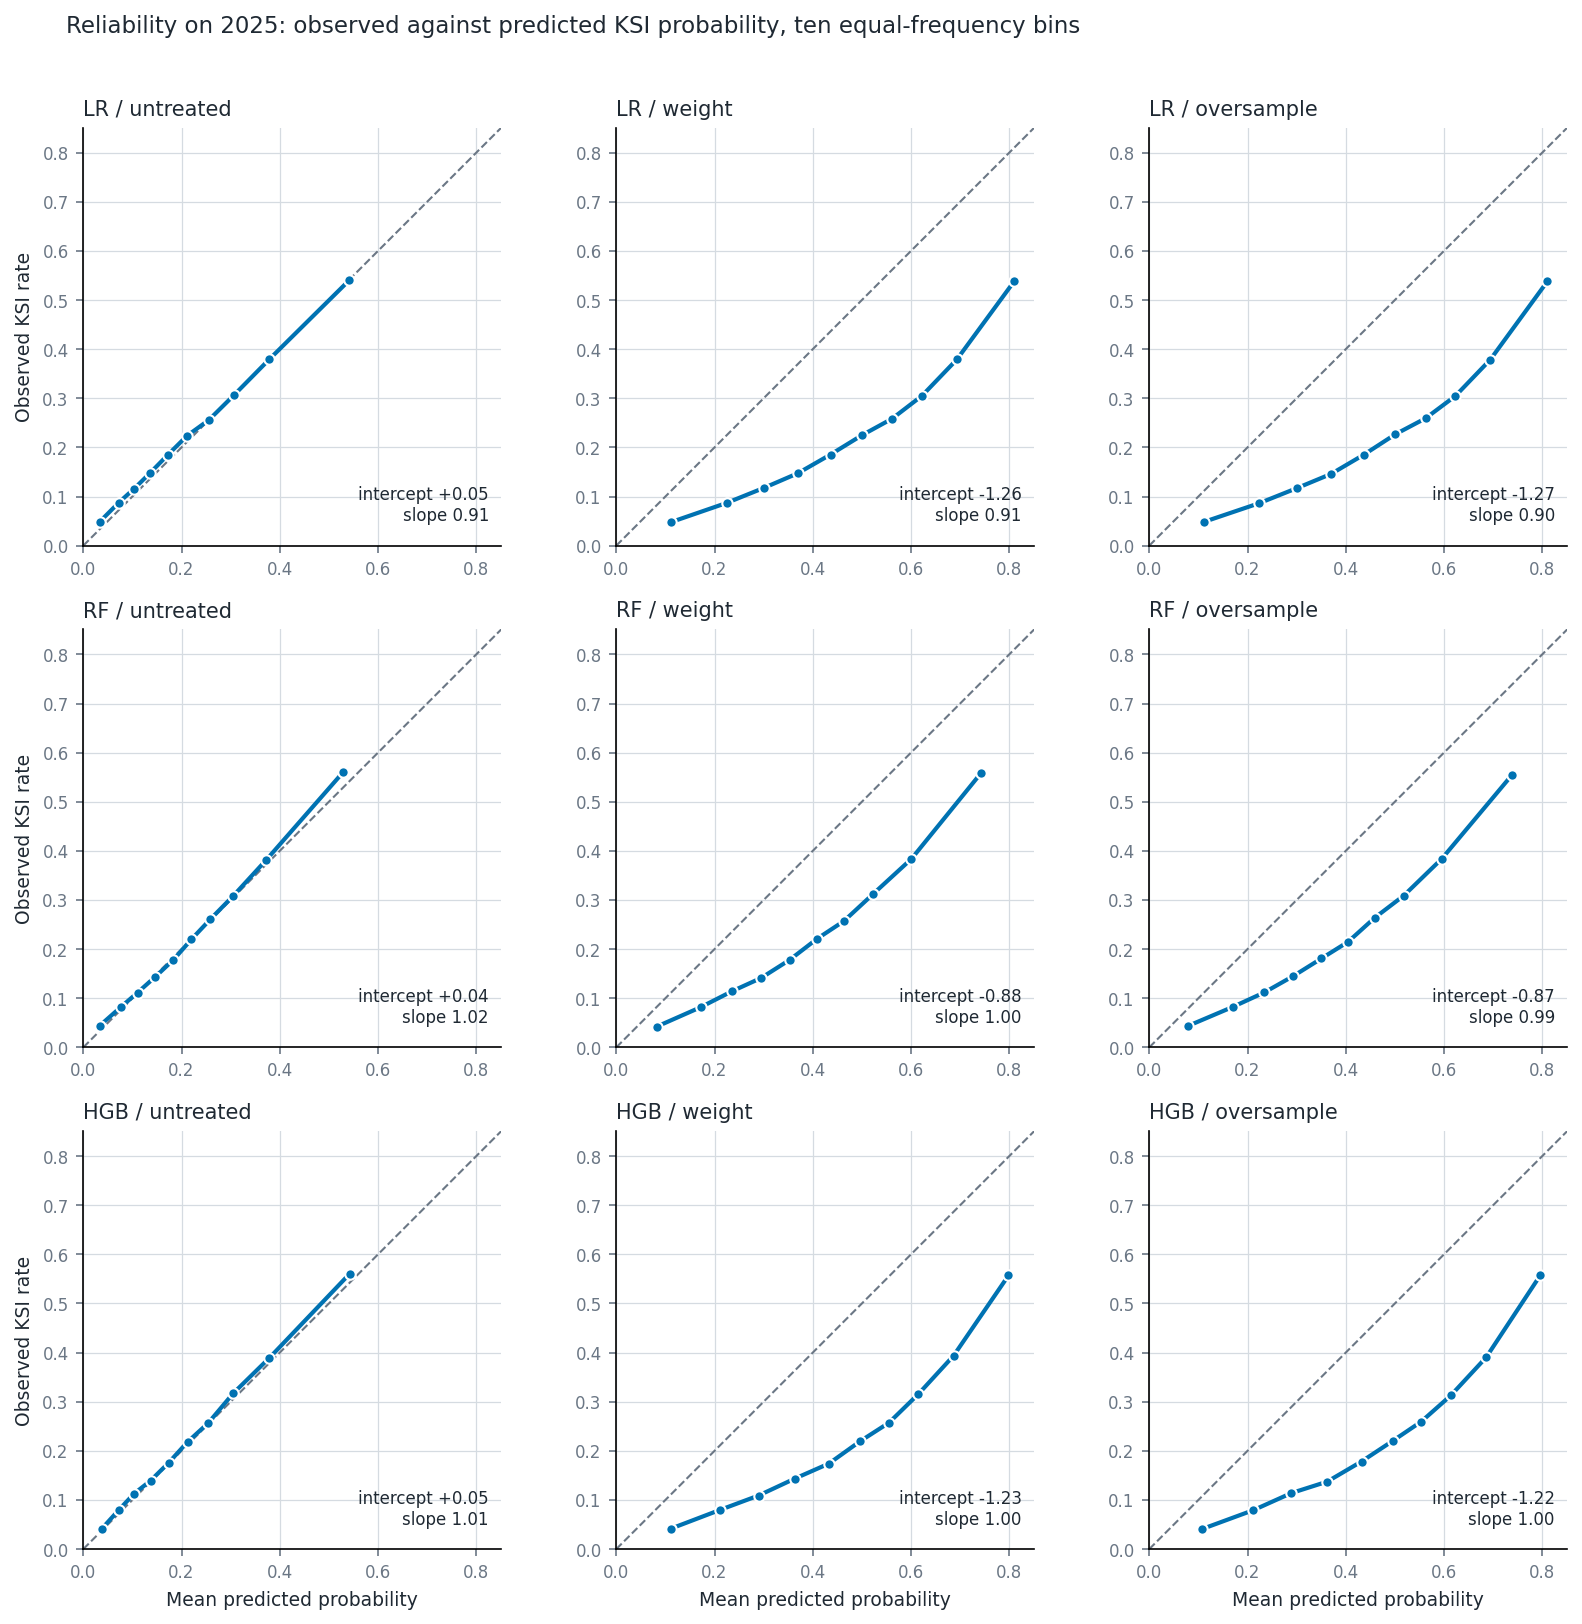

Saved reliability_2025.png and reliability_bins_2025.csv


In [9]:
# 8. Reliability plots: quantile bins, tied scores kept together ----------------------------------------
INK, GRID_C, MUTED = '#1f2933', '#d5dbe1', '#6b7785'
def bin_table(p):
    q = pd.qcut(p, 10, duplicates='drop')                    # equal-frequency bins; identical scores share a bin
    return pd.DataFrame({'p': p, 'y': y, 'bin': q}).groupby('bin', observed=True).agg(mean_pred=('p', 'mean'), observed=('y', 'mean'), n=('y', 'size')).reset_index(drop=True)
TABLES = {c: bin_table(P[c]) for c in COMBOS}
TOP = max(max(g['mean_pred'].max(), g['observed'].max()) for g in TABLES.values()) * 1.05      # one shared scale so panels compare
fig, axes = plt.subplots(3, 3, figsize=(11, 11), dpi=150)
bins_out = []
for ax, c in zip(axes.ravel(), COMBOS):
    g = TABLES[c].copy()
    g.insert(0, 'training', c[1]); g.insert(0, 'model', c[0]); bins_out.append(g)
    top = TOP
    ax.plot([0, top], [0, top], ls='--', lw=1, color=MUTED)
    ax.plot(g['mean_pred'], g['observed'], lw=2, color='#0072B2', marker='o', ms=5, mfc='#0072B2', mec='white', mew=1)
    ax.set_xlim(0, top); ax.set_ylim(0, top); ax.set_aspect('equal')
    ax.set_title(f'{c[0].upper()} / {c[1]}', fontsize=10, color=INK, loc='left')
    ax.text(0.97, 0.05, f"intercept {point[c]['cal_intercept']:+.2f}\nslope {point[c]['cal_slope']:.2f}", transform=ax.transAxes, ha='right', va='bottom', fontsize=8, color=INK)
    ax.grid(color=GRID_C, lw=0.6); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.tick_params(labelsize=8, colors=MUTED)
for ax in axes[-1]: ax.set_xlabel('Mean predicted probability', fontsize=9, color=INK)
for ax in axes[:, 0]: ax.set_ylabel('Observed KSI rate', fontsize=9, color=INK)
fig.suptitle('Reliability on 2025: observed against predicted KSI probability, ten equal-frequency bins', fontsize=11, color=INK, x=0.06, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(RES / 'reliability_2025.png', facecolor='white')
pd.concat(bins_out).round(5).to_csv(RES / 'reliability_bins_2025.csv', index=False)
plt.show()
print('Saved reliability_2025.png and reliability_bins_2025.csv')

In [10]:
# 9. Record what was done ----------------------------------------------------------------------------------
files = sorted(p.name for p in RES.glob('*'))
summary = dict(finished=dt.datetime.now().isoformat(timespec='seconds'), notebook='06', bootstrap_replicates=BOOT_REPS, bootstrap_seed=BOOT_SEED,
               logit_clip_bound=CLIP, interval='95% percentile', eval_module_sha256=EVAL_SHA, labels_sha256=label_sha, freeze_created=rec['created'],
               casualties_2025=int(len(df)), collisions_2025=int(n_coll), ksi_2025=int(y.sum()), outputs=files,
               output_sha256={f: sha(RES / f) for f in files if not f.startswith('bootstrap_draws')})
(RES / 'results_2025_summary.json').write_text(json.dumps(summary, indent=1))
print(json.dumps({k: v for k, v in summary.items() if k not in ('output_sha256',)}, indent=1))
print('\nNEXT: notebook 07 runs the pre-specified subgroup, recording-system and sensitivity analyses (3.7.5).')

{
 "finished": "2026-11-07T18:25:41",
 "notebook": "06",
 "bootstrap_replicates": 2000,
 "bootstrap_seed": 20261109,
 "logit_clip_bound": 1e-06,
 "interval": "95% percentile",
 "eval_module_sha256": "f3418de16c7259ff39b368fad2760257a1adde2e5cc53bfd7f1989b9815f9f87",
 "labels_sha256": "22ddae8fde110307daf9bd711a84f0b9cd18166d24e52194082b60e53cc3d4e3",
 "freeze_created": "2026-11-07T17:23:20",
 "casualties_2025": 127883,
 "collisions_2025": 101525,
 "ksi_2025": 29296,
 "outputs": [
  "bootstrap_draws_2025.parquet",
  "development_vs_2025.csv",
  "paired_contrasts_2025.csv",
  "reliability_2025.png",
  "reliability_bins_2025.csv",
  "results_2025_decisions.csv",
  "results_2025_score_measures.csv"
 ]
}

NEXT: notebook 07 runs the pre-specified subgroup, recording-system and sensitivity analyses (3.7.5).
